In [10]:
from google.colab import files

uploaded = files.upload()

Saving cleaned_dataset.xlsx.xlsx to cleaned_dataset.xlsx (1).xlsx


In [11]:
!pip install -q pandas numpy matplotlib seaborn openpyxl

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [14]:
import os

print("Files available in Colab:")
print(os.listdir("/content"))

Files available in Colab:
['.config', 'cleaned_dataset.xlsx.xlsx', '.ipynb_checkpoints', 'cleaned_dataset.xlsx', 'cleaned_dataset.xlsx (1).xlsx', 'sample_data']


In [15]:
import os

print(os.listdir("/content"))

['.config', 'cleaned_dataset.xlsx.xlsx', '.ipynb_checkpoints', 'cleaned_dataset.xlsx', 'cleaned_dataset.xlsx (1).xlsx', 'sample_data']


In [16]:
import pandas as pd

file_path = "/content/cleaned_dataset.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Number of rows: 600
Number of columns: 9


,Reading_ID,Timestamp,Building_Type,Appliance,Energy_Consumption_kWh,Temperature_C,Occupancy_Percent,Tariff_Period,Renewable_Generation_kWh
0,EN0001,2026-01-01 00:00:00,Hospital,Refrigerator,0.106,26.8,16,Off-Peak,0.00
1,EN0002,2026-01-01 01:00:00,Hospital,Computers,0.438,22.9,0,Off-Peak,0.46
2,EN0003,2026-01-01 02:00:00,Shopping Mall,Water Heater,1.141,24.9,55,Off-Peak,0.28
3,EN0004,2026-01-01 03:00:00,Home,Refrigerator,0.145,22.8,18,Off-Peak,0.00
4,EN0005,2026-01-01 04:00:00,Shopping Mall,Computers,0.712,21.6,27,Off-Peak,0.28


In [17]:
print("Column names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe())

Column names:
['Reading_ID', 'Timestamp', 'Building_Type', 'Appliance', 'Energy_Consumption_kWh', 'Temperature_C', 'Occupancy_Percent', 'Tariff_Period', 'Renewable_Generation_kWh']

Missing values:
Reading_ID                  0
Timestamp                   0
Building_Type               0
Appliance                   0
Energy_Consumption_kWh      0
Temperature_C               0
Occupancy_Percent           0
Tariff_Period               0
Renewable_Generation_kWh    0
dtype: int64

Statistical summary:


,Timestamp,Energy_Consumption_kWh,Temperature_C,Occupancy_Percent,Renewable_Generation_kWh
count,600,600.000000,600.000000,600.000000,600.000000
mean,2026-01-13 11:30:00,1.238007,23.079833,24.133333,0.515400
min,2026-01-01 00:00:00,0.085000,8.400000,0.000000,0.000000
25%,2026-01-07 05:45:00,0.435000,20.400000,3.000000,0.000000
50%,2026-01-13 11:30:00,0.844000,23.300000,23.000000,0.280000
75%,2026-01-19 17:15:00,1.867250,26.000000,39.000000,0.842500
max,2026-01-25 23:00:00,5.380000,35.200000,87.000000,2.300000
std,NaN,1.067935,3.974809,20.425496,0.586031


In [18]:
# STEP 2: DATASET QUALITY CHECK

print("========== DATASET OVERVIEW ==========")

print("Total records:", df.shape[0])
print("Total columns:", df.shape[1])

print("\n========== COLUMN INFORMATION ==========")
df.info()

print("\n========== MISSING VALUES ==========")
print(df.isnull().sum())

print("\n========== DUPLICATE RECORDS ==========")
print("Duplicate rows:", df.duplicated().sum())

print("\n========== STATISTICAL SUMMARY ==========")
display(df.describe())

========== DATASET OVERVIEW ==========
Total records: 600
Total columns: 9

========== COLUMN INFORMATION ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Reading_ID                600 non-null    object        
 1   Timestamp                 600 non-null    datetime64[ns]
 2   Building_Type             600 non-null    object        
 3   Appliance                 600 non-null    object        
 4   Energy_Consumption_kWh    600 non-null    float64       
 5   Temperature_C             600 non-null    float64       
 6   Occupancy_Percent         600 non-null    int64         
 7   Tariff_Period             600 non-null    object        
 8   Renewable_Generation_kWh  600 non-null    float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(4)
memory usage: 42.3+ KB

========== MIS

,Timestamp,Energy_Consumption_kWh,Temperature_C,Occupancy_Percent,Renewable_Generation_kWh
count,600,600.000000,600.000000,600.000000,600.000000
mean,2026-01-13 11:30:00,1.238007,23.079833,24.133333,0.515400
min,2026-01-01 00:00:00,0.085000,8.400000,0.000000,0.000000
25%,2026-01-07 05:45:00,0.435000,20.400000,3.000000,0.000000
50%,2026-01-13 11:30:00,0.844000,23.300000,23.000000,0.280000
75%,2026-01-19 17:15:00,1.867250,26.000000,39.000000,0.842500
max,2026-01-25 23:00:00,5.380000,35.200000,87.000000,2.300000
std,NaN,1.067935,3.974809,20.425496,0.586031


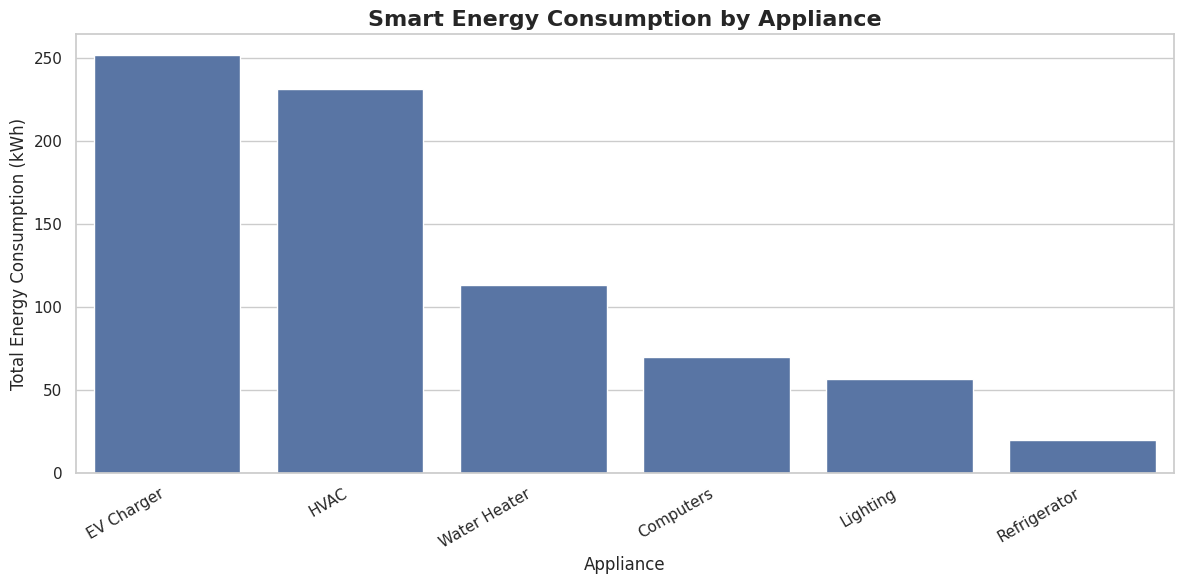

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate total energy consumption for each appliance
appliance_energy = (
    df.groupby("Appliance")["Energy_Consumption_kWh"]
    .sum()
    .sort_values(ascending=False)
)

# Create the chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=appliance_energy.index,
    y=appliance_energy.values
)

plt.title(
    "Smart Energy Consumption by Appliance",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Appliance", fontsize=12)
plt.ylabel("Total Energy Consumption (kWh)", fontsize=12)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

# Save chart for your GitHub project
plt.savefig(
    "/content/energy_by_appliance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

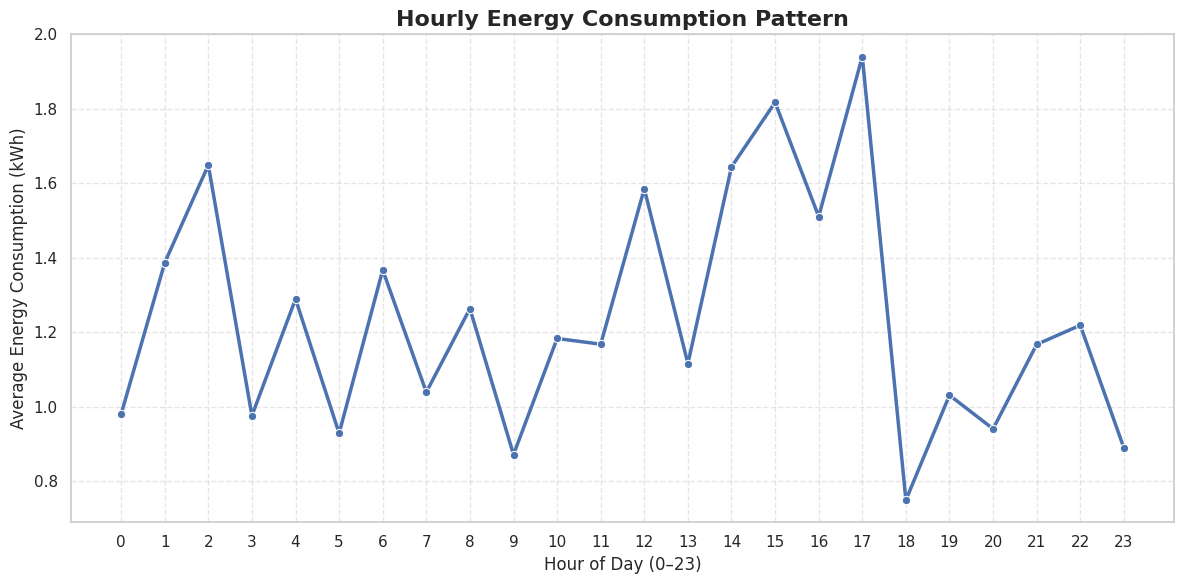

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Convert Timestamp into datetime format
df["Timestamp"] = pd.to_datetime(df["Timestamp"])

# Extract the hour from each timestamp
df["Hour"] = df["Timestamp"].dt.hour

# Calculate average energy consumption for each hour
hourly_energy = (
    df.groupby("Hour")["Energy_Consumption_kWh"]
    .mean()
)

# Create the line chart
plt.figure(figsize=(12, 6))

sns.lineplot(
    x=hourly_energy.index,
    y=hourly_energy.values,
    marker="o",
    linewidth=2.5
)

plt.title(
    "Hourly Energy Consumption Pattern",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Hour of Day (0–23)", fontsize=12)
plt.ylabel("Average Energy Consumption (kWh)", fontsize=12)
plt.xticks(range(0, 24))
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

# Save the chart
plt.savefig(
    "/content/hourly_energy_consumption.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
peak_hour = hourly_energy.idxmax()
peak_consumption = hourly_energy.max()

lowest_hour = hourly_energy.idxmin()
lowest_consumption = hourly_energy.min()

print("========== HOURLY ENERGY INSIGHTS ==========")
print(f"Peak consumption hour: {peak_hour}:00")
print(f"Average consumption at peak: {peak_consumption:.3f} kWh")

print(f"\nLowest consumption hour: {lowest_hour}:00")
print(f"Average consumption at lowest hour: {lowest_consumption:.3f} kWh")

========== HOURLY ENERGY INSIGHTS ==========
Peak consumption hour: 17:00
Average consumption at peak: 1.941 kWh

Lowest consumption hour: 18:00
Average consumption at lowest hour: 0.749 kWh


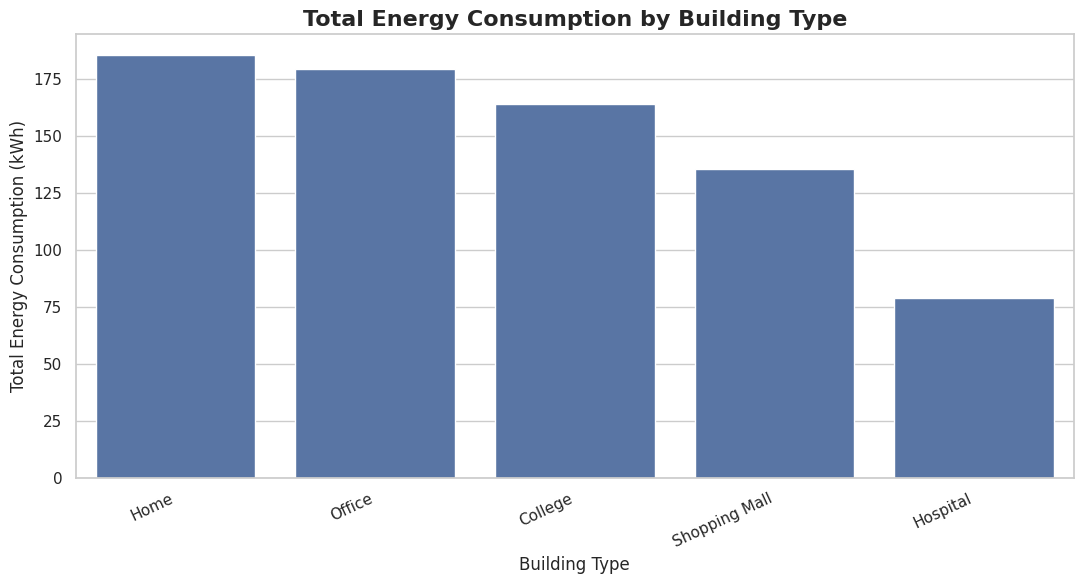

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate total consumption by building type
building_energy = (
    df.groupby("Building_Type")["Energy_Consumption_kWh"]
    .sum()
    .sort_values(ascending=False)
)

# Create a bar chart
plt.figure(figsize=(11, 6))

sns.barplot(
    x=building_energy.index,
    y=building_energy.values
)

plt.title(
    "Total Energy Consumption by Building Type",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Building Type", fontsize=12)
plt.ylabel("Total Energy Consumption (kWh)", fontsize=12)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()

# Save the chart
plt.savefig(
    "/content/building_energy_consumption.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
highest_building = building_energy.idxmax()
highest_usage = building_energy.max()

print("========== BUILDING ENERGY INSIGHTS ==========")
print("Highest-consuming building type:", highest_building)
print(f"Total energy consumption: {highest_usage:.3f} kWh")

print("\n========== ALL BUILDING TYPES ==========")
display(building_energy.reset_index(name="Total_Energy_kWh"))

========== BUILDING ENERGY INSIGHTS ==========
Highest-consuming building type: Home
Total energy consumption: 185.299 kWh

========== ALL BUILDING TYPES ==========


,Building_Type,Total_Energy_kWh
0,Home,185.299
1,Office,179.343
2,College,163.994
3,Shopping Mall,135.413
4,Hospital,78.755


In [24]:
building_average = (
    df.groupby("Building_Type")["Energy_Consumption_kWh"]
    .mean()
    .sort_values(ascending=False)
)

print("Average energy consumption per reading:")
display(building_average.reset_index(name="Average_Energy_kWh"))

Average energy consumption per reading:


,Building_Type,Average_Energy_kWh
0,Shopping Mall,1.381765
1,Office,1.379562
2,Hospital,1.270242
3,College,1.197036
4,Home,1.071092


========== ENERGY COMPARISON ==========
Total consumption: 742.80 kWh
Total renewable generation: 309.24 kWh


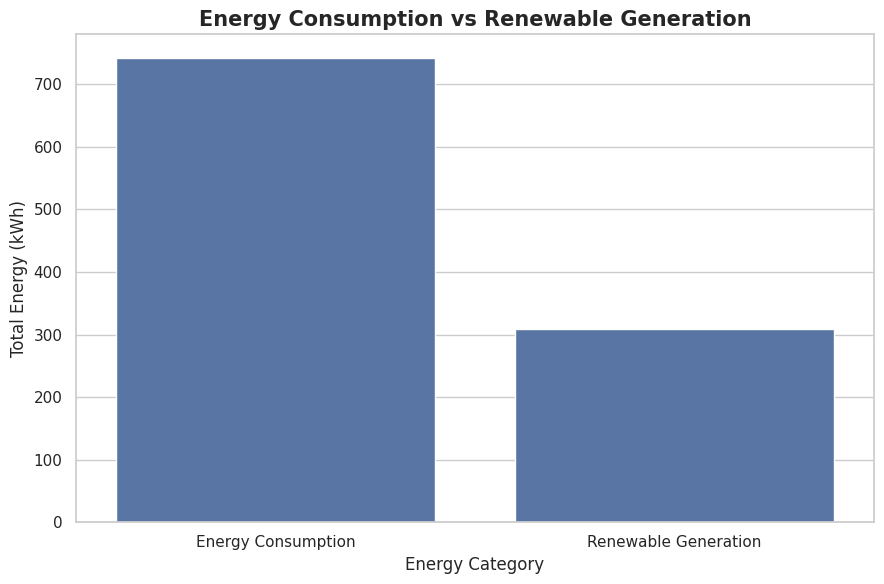

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate total consumption and renewable generation
energy_comparison = df[
    ["Energy_Consumption_kWh", "Renewable_Generation_kWh"]
].sum()

print("========== ENERGY COMPARISON ==========")
print(f"Total consumption: {energy_comparison['Energy_Consumption_kWh']:.2f} kWh")
print(f"Total renewable generation: {energy_comparison['Renewable_Generation_kWh']:.2f} kWh")

# Create a comparison chart
plt.figure(figsize=(9, 6))

sns.barplot(
    x=["Energy Consumption", "Renewable Generation"],
    y=[
        energy_comparison["Energy_Consumption_kWh"],
        energy_comparison["Renewable_Generation_kWh"]
    ]
)

plt.title(
    "Energy Consumption vs Renewable Generation",
    fontsize=15,
    fontweight="bold"
)
plt.ylabel("Total Energy (kWh)")
plt.xlabel("Energy Category")
plt.tight_layout()

plt.savefig(
    "/content/energy_vs_renewables.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
total_consumption = df["Energy_Consumption_kWh"].sum()
total_renewable = df["Renewable_Generation_kWh"].sum()

renewable_ratio = (total_renewable / total_consumption) * 100

print(f"Renewable generation / consumption: {renewable_ratio:.2f}%")

if renewable_ratio >= 100:
    print("Total renewable generation is at least equal to total consumption.")
else:
    print("Total renewable generation is below total consumption.")

Renewable generation / consumption: 41.63%
Total renewable generation is below total consumption.


In [33]:
# Rank appliance categories by total energy consumption
appliance_summary = (
    df.groupby("Appliance")["Energy_Consumption_kWh"]
    .agg(["sum", "mean", "count"])
    .sort_values("sum", ascending=False)
    .reset_index()
)

appliance_summary.columns = [
    "Appliance",
    "Total_Consumption_kWh",
    "Average_Consumption_kWh",
    "Number_of_Readings"
]

display(appliance_summary)

print("\n========== OPTIMIZATION OPPORTUNITIES ==========")

top_appliance = appliance_summary.iloc[0]["Appliance"]

print("Highest-consuming appliance category:", top_appliance)
print("Investigate its operating schedule, efficiency, and unnecessary usage.")

,Appliance,Total_Consumption_kWh,Average_Consumption_kWh,Number_of_Readings
0,EV Charger,251.755,2.961824,85
1,HVAC,231.117,2.201114,105
2,Water Heater,113.498,1.134980,100
3,Computers,69.723,0.749710,93
4,Lighting,56.772,0.506893,112
5,Refrigerator,19.939,0.189895,105



========== OPTIMIZATION OPPORTUNITIES ==========
Highest-consuming appliance category: EV Charger
Investigate its operating schedule, efficiency, and unnecessary usage.


In [34]:
import os
import zipfile
from google.colab import files

chart_files = [
    "/content/energy_by_appliance.png",
    "/content/hourly_energy_consumption.png",
    "/content/building_energy_consumption.png",
    "/content/energy_vs_renewables.png"
]

zip_path = "/content/energy_visualizations.zip"

with zipfile.ZipFile(zip_path, "w") as zip_file:
    for file_path in chart_files:
        if os.path.exists(file_path):
            zip_file.write(file_path, arcname=os.path.basename(file_path))
        else:
            print("Chart not found:", os.path.basename(file_path))

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
# STEP 9: AUTOMATIC PROJECT FINDINGS

import pandas as pd

# 1. Appliance analysis
appliance_totals = df.groupby("Appliance")[
    "Energy_Consumption_kWh"
].sum().sort_values(ascending=False)

# 2. Building analysis
building_totals = df.groupby("Building_Type")[
    "Energy_Consumption_kWh"
].sum().sort_values(ascending=False)

# 3. Hourly analysis
df["Timestamp"] = pd.to_datetime(df["Timestamp"])
df["Hour"] = df["Timestamp"].dt.hour

hourly_average = df.groupby("Hour")[
    "Energy_Consumption_kWh"
].mean()

# 4. Renewable generation analysis
total_consumption = df["Energy_Consumption_kWh"].sum()
total_renewable = df["Renewable_Generation_kWh"].sum()

print("=" * 55)
print("SMART ENERGY CONSUMPTION AND OPTIMIZATION")
print("PROJECT FINDINGS")
print("=" * 55)

print(f"\nTotal readings: {len(df)}")
print(f"Total energy consumption: {total_consumption:.2f} kWh")
print(f"Total renewable generation: {total_renewable:.2f} kWh")

print("\n1. HIGHEST-CONSUMING APPLIANCE")
print("Appliance:", appliance_totals.idxmax())
print(f"Consumption: {appliance_totals.max():.2f} kWh")

print("\n2. HIGHEST-CONSUMING BUILDING TYPE")
print("Building:", building_totals.idxmax())
print(f"Consumption: {building_totals.max():.2f} kWh")

print("\n3. HOUR WITH HIGHEST AVERAGE CONSUMPTION")
print(f"Hour: {hourly_average.idxmax():02d}:00")
print(f"Average: {hourly_average.max():.3f} kWh per reading")

print("\n4. HOUR WITH LOWEST AVERAGE CONSUMPTION")
print(f"Hour: {hourly_average.idxmin():02d}:00")
print(f"Average: {hourly_average.min():.3f} kWh per reading")

print("\n5. APPLIANCE CONSUMPTION RANKING")
display(appliance_totals.reset_index(
    name="Total_Consumption_kWh"
))

print("\n6. BUILDING CONSUMPTION RANKING")
display(building_totals.reset_index(
    name="Total_Consumption_kWh"
))

SMART ENERGY CONSUMPTION AND OPTIMIZATION
PROJECT FINDINGS

Total readings: 600
Total energy consumption: 742.80 kWh
Total renewable generation: 309.24 kWh

1. HIGHEST-CONSUMING APPLIANCE
Appliance: EV Charger
Consumption: 251.75 kWh

2. HIGHEST-CONSUMING BUILDING TYPE
Building: Home
Consumption: 185.30 kWh

3. HOUR WITH HIGHEST AVERAGE CONSUMPTION
Hour: 17:00
Average: 1.941 kWh per reading

4. HOUR WITH LOWEST AVERAGE CONSUMPTION
Hour: 18:00
Average: 0.749 kWh per reading

5. APPLIANCE CONSUMPTION RANKING


,Appliance,Total_Consumption_kWh
0,EV Charger,251.755
1,HVAC,231.117
2,Water Heater,113.498
3,Computers,69.723
4,Lighting,56.772
5,Refrigerator,19.939



6. BUILDING CONSUMPTION RANKING


,Building_Type,Total_Consumption_kWh
0,Home,185.299
1,Office,179.343
2,College,163.994
3,Shopping Mall,135.413
4,Hospital,78.755


In [36]:
from pathlib import Path

report = f"""
SMART ENERGY CONSUMPTION AND OPTIMIZATION
PROJECT ANALYSIS REPORT

1. PROJECT OVERVIEW
This project analyzes synthetic energy consumption data to
explore appliance usage, building demand, hourly patterns,
and renewable energy generation.

2. DATASET SUMMARY
Number of readings: {len(df)}
Number of columns: {df.shape[1]}
Total energy consumption: {total_consumption:.2f} kWh
Total renewable generation: {total_renewable:.2f} kWh

3. KEY FINDINGS
Highest-consuming appliance: {appliance_totals.idxmax()}
Its total consumption: {appliance_totals.max():.2f} kWh

Highest-consuming building type: {building_totals.idxmax()}
Its total consumption: {building_totals.max():.2f} kWh

Peak average consumption hour: {hourly_average.idxmax():02d}:00
Peak average reading: {hourly_average.max():.3f} kWh

Lowest average consumption hour: {hourly_average.idxmin():02d}:00
Lowest average reading: {hourly_average.min():.3f} kWh

4. OPTIMIZATION OPPORTUNITIES
- Investigate operating schedules for high-consuming appliances.
- Review energy use during high-demand hours.
- Evaluate suitable energy-saving operating practices.
- Compare renewable generation and demand over matching intervals.

5. LIMITATIONS
The dataset is synthetic and does not represent actual
building measurements. Findings are illustrative.
No real-world energy savings are claimed.

6. CONCLUSION
The analysis provides a starting point for identifying
energy optimization opportunities. Recommendations should
be validated using real energy measurements.
"""

Path("/content/energy_analysis_report.txt").write_text(
    report, encoding="utf-8"
)

print(report)
print("\nReport saved successfully!")


SMART ENERGY CONSUMPTION AND OPTIMIZATION
PROJECT ANALYSIS REPORT

1. PROJECT OVERVIEW
This project analyzes synthetic energy consumption data to
explore appliance usage, building demand, hourly patterns,
and renewable energy generation.

2. DATASET SUMMARY
Number of readings: 600
Number of columns: 10
Total energy consumption: 742.80 kWh
Total renewable generation: 309.24 kWh

3. KEY FINDINGS
Highest-consuming appliance: EV Charger
Its total consumption: 251.75 kWh

Highest-consuming building type: Home
Its total consumption: 185.30 kWh

Peak average consumption hour: 17:00
Peak average reading: 1.941 kWh

Lowest average consumption hour: 18:00
Lowest average reading: 0.749 kWh

4. OPTIMIZATION OPPORTUNITIES
- Investigate operating schedules for high-consuming appliances.
- Review energy use during high-demand hours.
- Evaluate suitable energy-saving operating practices.
- Compare renewable generation and demand over matching intervals.

5. LIMITATIONS
The dataset is synthetic and do

In [37]:
from google.colab import files
files.download("/content/energy_analysis_report.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>